# Import a Biacore Cycle/Fc text export

Import **`biacore_cycle_fc.tsv`**, inspect its metadata, and plot the measured
sensorgrams. This example uses a full-resolution selection committed with the repository;
it compares candidate fits and assesses their scientific limitations. No data download is required.

**Data origin:** [RKI-ZBS Biacore T200 binning sensorgrams](https://github.com/RKI-ZBS/SPR_kinetics_binning/blob/ceaae964586dcbb00ac53bcae301bc097d92f3f4/Binning/Binning_Raw_Inspector_T200/input/2022-05-10_Kurven_Binning_huCapRaw.txt). Copyright (c) 2024 SternDan, MIT license.
This is a modified excerpt/conversion; the exact changes and pinned sources
are listed in [SOURCES.md](data/spr_exports/SOURCES.md).
The data and plotted sensorgrams retain their upstream license:
[full license notice](../test_files/spr_exports/SPR_kinetics_binning-LICENSE).

In [1]:
from pathlib import Path
import sys
import warnings
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

%matplotlib inline

# Works from the repository root, notebooks/, or docs/notebooks/.
cwd = Path.cwd().resolve()
repo_root = next(
    path for path in (cwd, *cwd.parents)
    if (path / "src" / "pykingenie").is_dir()
    and (path / "test_files" / "spr_exports").is_dir()
)
for path in [repo_root / "src", repo_root / "notebooks"]:
    sys.path.insert(0, str(path))
from pykingenie import detect_file_format, SprTextExperiment, KineticsAnalyzer, plot_plate_info

plt.rcParams.update({"figure.dpi": 110, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
data_file = repo_root / "notebooks" / "data" / "spr_exports" / "biacore_cycle_fc.tsv"
print("Input:", data_file.name)
fit_metadata = json.loads((data_file.parent / "fit_metadata.json").read_text())[data_file.stem]

Input: biacore_cycle_fc.tsv


## File layout and representative selection

Tab-separated `Cycle=..._Fc=..._X` / `_Y` pairs with decimal commas. This file retains the complete original cycles 1 and 2 at their recorded sampling resolution (1,105 and 1,104 points). No measurements are removed or downsampled.

This is an epitope-binning run, not a single association/dissociation experiment. The complete cycles contain large protocol transitions. The plot shows the full record and an early-cycle zoom of the same raw data; the zoom changes only the display limits. No baseline or bulk correction is applied. Headers contain no analyte concentrations, so the concentration table remains `NaN`.

These exports do not establish injection-event timing. The boundaries below
are **provisional inferred events**, without independent experimental verification.
The sensorgram plot rejoins all partitions on the original time grid.
Verify actual injection timing and concentrations before fitting. Boundaries
are seconds, and association is `[association_start, association_end)`.

The expected missing-concentration warning is displayed below.
`sample_id="unassigned"` is a grouping placeholder, not a recovered sample identity.

The kinetic section makes the provisional event boundaries explicit and tests
±1 s timing changes. They are inferred from transitions, not recovered event logs.
No molar concentration is assigned to this experiment.

In [2]:
association_start = fit_metadata["association_start"]
association_end = fit_metadata["association_end"]

print("Detected layout:", detect_file_format(data_file))

experiment = SprTextExperiment("biacore_cycle_fc")
with warnings.catch_warnings(record=True) as messages:
    warnings.simplefilter("always", UserWarning)
    experiment.read_file(
        data_file,
        association_start=association_start,
        association_end=association_end,
        decimal=',',
        time_unit="s",
        sample_id="unassigned",
    )
for message in messages:
    print(message.message)
print(f"Imported {experiment.no_sensors} measured curves; {experiment.no_steps} API phases.")
assert experiment.traces_loaded and experiment.no_sensors == 2

Detected layout: spr_text
Some analyte concentrations are unavailable or have no unit. Provide concentrations or edit ligand_conc_df before fitting.
Imported 2 measured curves; 3 API phases.


## Available curve information

Each measured curve becomes a sensor in the experiment object. Its complete
original label remains in `sensor_names`. The following table extracts only
the header/row-label fields present in this specific example file.

In [3]:
curve_ids = [f"Curve {i + 1}" for i in range(experiment.no_sensors)]
labels = pd.Series(experiment.sensor_names, name="Exported label")
header_info = labels.str.extract('Cycle=(?P<Cycle>\\d+)_Fc=(?P<Flow_cell>.+)$')
header_info.insert(0, "Curve", curve_ids)
display(header_info)
display(labels.to_frame())
plot_labels = [f"Cycle {row.Cycle} / Fc{row.Flow_cell}" for row in header_info.itertuples()]

,Curve,Cycle,Flow_cell
0,Curve 1,1,4-3
1,Curve 2,2,4-3


,Exported label
0,Cycle=1_Fc=4-3
1,Cycle=2_Fc=4-3


## Concentration metadata

`NaN` means a molar concentration is unavailable, not zero concentration.
Before fitting, supply your verified values through `concentrations` and
`concentration_unit` at import, or update `ligand_conc_df`. A list follows the
measured-curve order; a mapping can use full exported curve labels as keys.

In [4]:
concentration_info = experiment.ligand_conc_df.copy()
concentration_info.insert(0, "Curve", curve_ids)
display(concentration_info[["Curve", "Concentration_micromolar", "SampleID"]])
assert concentration_info["Concentration_micromolar"].isna().all()

,Curve,Concentration_micromolar,SampleID
0,Curve 1,NaN,unassigned
1,Curve 2,NaN,unassigned


## Plate information, when available

The `Fc=4-3` value is a flow-cell identifier, not a well coordinate. This curve export does not contain a sample-plate layout.

The conditional cell below uses `plot_plate_info` only when the experiment
actually contains the required plate metadata. It prints a message for this
file rather than assigning artificial well positions.

In [5]:
analyzer = KineticsAnalyzer()
analyzer.add_experiment(experiment, experiment.name)
plate_fields = (
    "sample_row", "sample_column", "sample_type", "sample_id", "sample_conc_labeled"
)
have_plate_info = all(
    getattr(experiment, field) is not None
    and len(getattr(experiment, field)) > 0
    for field in plate_fields
)
if have_plate_info:
    display(pd.DataFrame({field: getattr(experiment, field) for field in plate_fields}))
    plot_plate_info(analyzer, experiment.name).show()
else:
    print("No plate-well coordinates are available in this export; no plate plot is created.")

No plate-well coordinates are available in this export; no plate plot is created.


## Imported sensorgrams

Every finite source observation in the selected curves is plotted at its original
time. No resampling, smoothing or baseline subtraction is applied. Lines break
across gaps larger than three median sampling intervals. Legend entries use the
original concentration labels or cycle/flow-cell identifiers shown above.

The right panel is a display zoom; the complete binning cycles remain visible on the left.

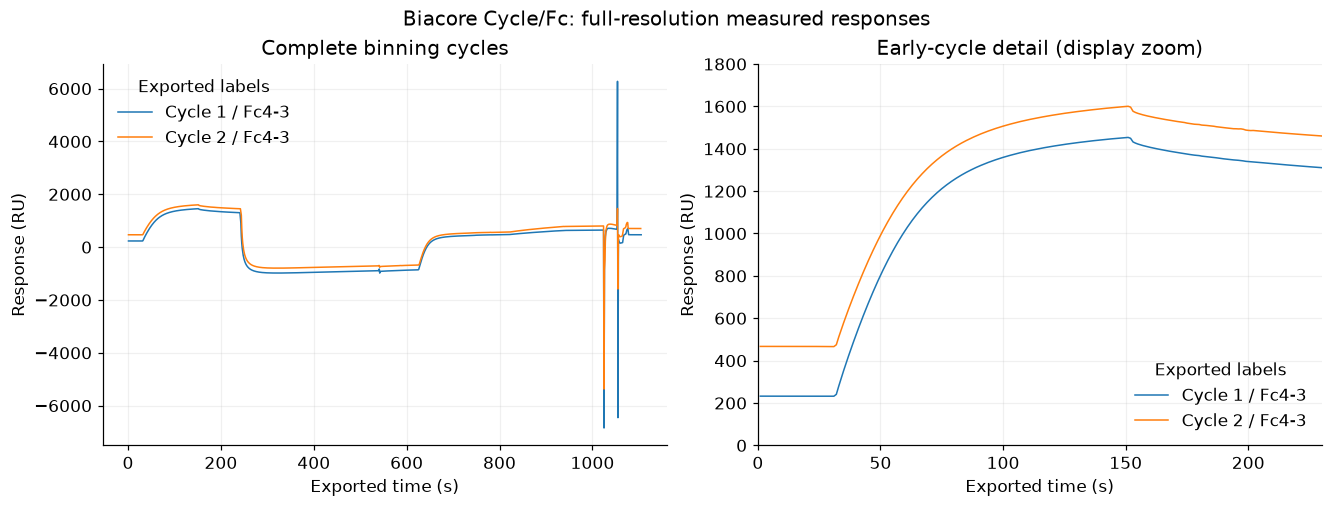

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for i, label in enumerate(plot_labels):
    time = np.concatenate(experiment.xs[i])
    response = np.concatenate(experiment.ys[i])
    breaks = np.flatnonzero(np.diff(time) > 3 * np.median(np.diff(time))) + 1
    segments = np.split(np.arange(len(time)), breaks)
    for axis in axes:
        for j, indices in enumerate(segments):
            axis.plot(time[indices], response[indices], color=f"C{i}", linewidth=1,
                      label=label if j == 0 else None)
for axis in axes:
    axis.set(xlabel="Exported time (s)", ylabel="Response (RU)")
    axis.legend(frameon=False, title="Exported labels")
    axis.grid(alpha=0.18)
axes[0].set_title("Complete binning cycles")
axes[1].set(title="Early-cycle detail (display zoom)", xlim=(0, 230), ylim=(0, 1800))
fig.suptitle("Biacore Cycle/Fc: full-resolution measured responses")
plt.show()

## Check the retained points and import partitions

The original times remain in `xs`; `ys` contains the corresponding measured
responses. Duke phase times come from the companion metadata. The rstoolbox and
binning phase boundaries remain provisional. For binning, post-event data include
later protocol steps; the fit below uses only an explicitly limited early episode.

In [7]:
imported_points = pd.DataFrame([
    {
        "Curve": curve_ids[i],
        "Baseline points": len(experiment.xs[i][0]),
        "Association points": len(experiment.xs[i][1]),
        "Dissociation points": len(experiment.xs[i][2]),
        "Total points": sum(len(step) for step in experiment.xs[i]),
        "First exported time (s)": np.concatenate(experiment.xs[i])[0],
        "Last exported time (s)": np.concatenate(experiment.xs[i])[-1],
    }
    for i in range(experiment.no_sensors)
])
display(imported_points)
display(experiment.df_steps[["Name", "Type", "Start"]])

,Curve,Baseline points,Association points,Dissociation points,Total points,First exported time (s),Last exported time (s)
0,Curve 1,29,120,956,1105,1.0,1105.0
1,Curve 2,29,120,955,1104,1.0,1104.0


,Name,Type,Start
0,Baseline,BASELINE,1.0
1,Association,ASSOC,30.0
2,Dissociation,DISASSOC,150.0


All finite source observations in the teaching selections remain available in
the import. The fitting masks below leave transition regions out of the objective;
they do not remove observations from the experiment or shift the physical clock.
Source selection, omitted missing pairs and data licenses:
[SOURCES.md](data/spr_exports/SOURCES.md).

## Fitting setup and physical assumptions

This is a **binning protocol**, not one association/dissociation experiment.
No analyte concentrations or event log are available. Do not fit the whole run to
a binding model or fabricate a concentration. Fit only the early episode using
inferred start 30 s, switch 150 s and end 230 s. Compare empirical single-exponential
association/decay with shared rates, independent rates, and a two-component
exponential description. Amplitudes are per curve. Their fitted rates are **k_obs
and decay constants**, not intrinsic kon/koff/Kd. Timing sensitivity is essential.

In [8]:
display(pd.DataFrame({
    "Curve": curve_ids,
    "Fit concentration": fit_metadata["concentrations"] or ["unavailable"] * len(curve_ids),
    "Concentration unit": fit_metadata["concentration_unit"] or "not assigned",
}))
display(pd.Series({key: fit_metadata[key] for key in (
    "association_start", "association_end", "fit_end", "timing_verified",
    "molar_concentrations_verified", "regenerated", "bulk_shift", "initial_occupancy", "protocol"
)}).to_frame("Fit metadata"))
for source in fit_metadata["sources"]:
    print("Metadata/source:", source)

,Curve,Fit concentration,Concentration unit
0,Curve 1,unavailable,not assigned
1,Curve 2,unavailable,not assigned


,Fit metadata
association_start,30
association_end,150
fit_end,230
timing_verified,False
molar_concentrations_verified,False
regenerated,None
bulk_shift,False
initial_occupancy,background subtracted for early-cycle descript...
protocol,Binning protocol; inferred early episode only....


Metadata/source: https://github.com/RKI-ZBS/SPR_kinetics_binning/blob/ceaae964586dcbb00ac53bcae301bc097d92f3f4/Binning/Binning_Raw_Inspector_T200/input/2022-05-10_Kurven_Binning_huCapRaw.txt


## Compare candidate models on identical observations

The notebook driver uses **pyKinGenie's forward binding functions** and SciPy
bounded least squares, with eight reproducible starting points (seed 2918).
It retains the true injection clock and propagates state at the physical switch,
including when transition points are masked. See [spr_fitting.py](spr_fitting.py).

Exclude 3 s around injection transitions; fit at most one original observation
per second, without averaging. Carterra's slower records retain their native
spacing. This reduces oversampling but does **not** establish independent errors.
Background/initial response estimates come from the stated pre-injection window
and are held fixed; the sensitivity analysis does not make those estimates exact.

Every candidate uses the same selected observations. BIC is
`n*log(RSS/n) + k*log(n)`; `k` includes rates, fractions, per-curve capacities and
RI terms. Lower BIC ranks these candidates **conditional on the noise/model
assumptions**. Reduced χ² here is `RSS/(n-k)` with unit variance; it is not a
calibrated chi-square goodness-of-fit test, and a value below 1 is not validation.

In [9]:
from spr_fitting import run_analysis, parameter_table, plot_fit, trust_assessment

analysis = run_analysis(experiment, fit_metadata, n_starts=8, sensitivity=True)
display(analysis["comparison"].style.format(precision=4, na_rep="not identified"))
if not analysis["failures"].empty:
    display(analysis["failures"])

# Optional: export the numerical audit report with
# from spr_fitting import save_report
# save_report(analysis, "my_fit_report.json", data_file.stem)

,Model,Rmax,Parameters,Points,Reduced χ² (unit variance),RMSE,BIC,ΔBIC,Jacobian condition,Max |parameter correlation|,Near bounds,Converged starts
0,double_exp,local,7,386,274.5925,16.4199,2202.1279,0.0000,227392.5035,1.0000,,8/8
1,single_exp_shared_rates,local,4,386,407.4704,20.0810,2339.6503,137.5224,4.0544,0.7462,,8/8
2,single_exp,local,6,386,408.2493,20.0475,2350.2728,148.1449,4.0861,0.8155,,8/8


## Lowest-BIC fit and residuals

Thin solid lines are the imported data; dashed lines are the selected fitted
curves. Grey bands indicate excluded transition regions. The residual panel is
essential: an excellent-looking overlay can still have long systematic errors.
For binning, this figure shows only the fitted early episode.

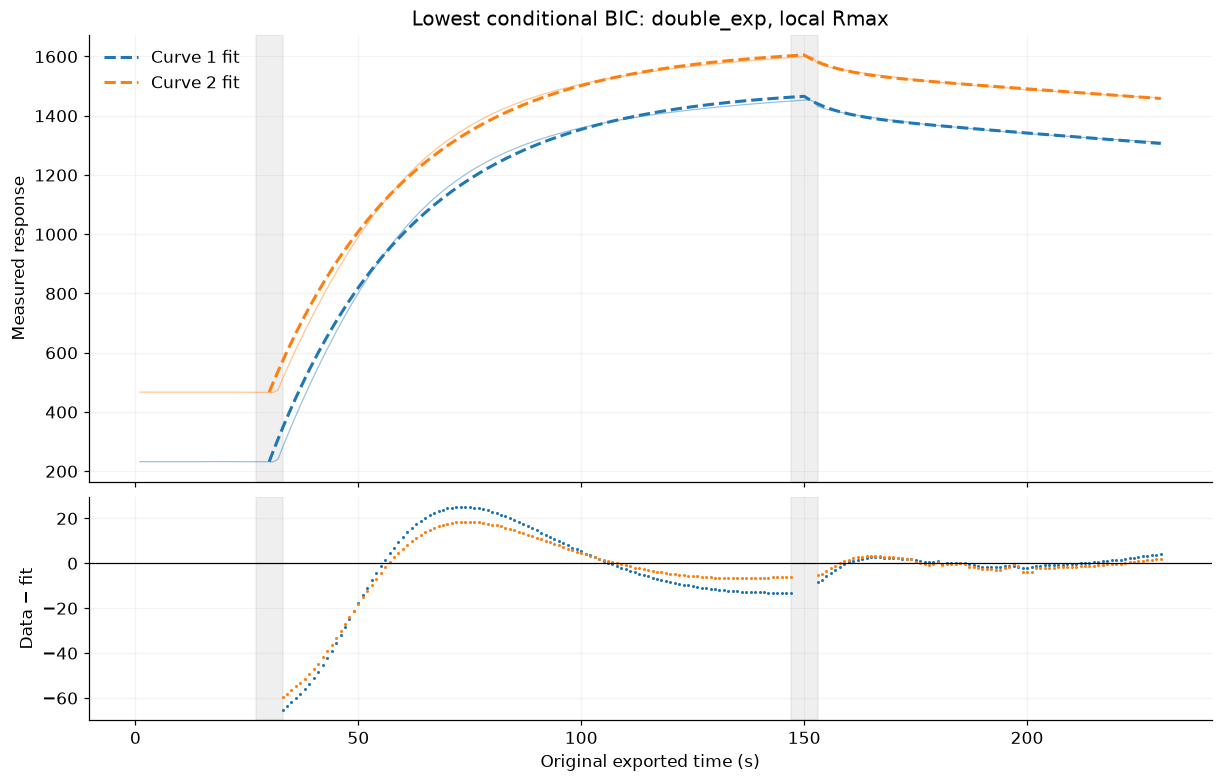

In [10]:
fig_fit = plot_fit(analysis)
plt.show()

## Parameters and identifiability

Intervals below are **nominal local iid least-squares intervals**, conditional
on the chosen model, fixed baseline/initial signal, event times and input
concentrations. Correlated residuals or model mismatch make them overconfident.
They are not bootstrap/profile intervals or proof of a molecular mechanism.
Derived `k_on = k_off/Kd` entries are point estimates; no interval is claimed.
Extreme intervals, near-unit correlations and near-bound parameters indicate
that individual parameters should not be interpreted.

In [11]:
display(parameter_table(analysis).style.format({
    "Estimate": "{:.4g}", "Conditional 95% lower": "{:.4g}",
    "Conditional 95% upper": "{:.4g}",
}, na_rep="not profiled/identified"))
display(analysis["best"]["correlation"].style.format(precision=3, na_rep="not identified"))
display(analysis["best"]["residuals"].style.format(precision=4))

,Parameter,Unit,Estimate,Conditional 95% lower,Conditional 95% upper
0,k_obs1,1/s,0.0313,8.052e-270,1.217e+266
1,k_decay1,1/s,0.001074,0.0008989,0.001283
2,k_obs2,1/s,0.0313,1e-300,1e+300
3,k_decay2,1/s,0.138,0.08317,0.2288
4,fraction,dimensionless,0.9491,-51.6,53.5
5,Rmax_1,RU,1263,1247,1279
6,Rmax_2,RU,1165,1151,1180


,k_obs1,k_decay1,k_obs2,k_decay2,fraction,Rmax_1,Rmax_2
k_obs1,1.000,-0.055,-1.000,-0.175,-1.000,-0.931,-0.928
k_decay1,-0.055,1.000,0.055,0.733,0.055,0.069,0.069
k_obs2,-1.000,0.055,1.000,0.175,1.000,0.931,0.928
k_decay2,-0.175,0.733,0.175,1.000,0.175,0.218,0.217
fraction,-1.000,0.055,1.000,0.175,1.000,0.931,0.928
Rmax_1,-0.931,0.069,0.931,0.218,0.931,1.000,0.966
Rmax_2,-0.928,0.069,0.928,0.217,0.928,0.966,1.000


,Curve,Points,RMSE,Lag-1 residual correlation,Baseline noise estimate,RMSE / baseline noise
0,Cycle=1_Fc=4-3,193,17.6343,0.9982,0.0126,1401.7403
1,Cycle=2_Fc=4-3,193,15.1082,0.9983,0.0556,271.9108


## Sensitivity of the selected model

Refit the selected family after changing trimming, sampling interval,
dissociation-window length and event times. Parameter entries are **ratios to
the primary fit**: 1 means unchanged, 1.5 means 50% higher. These runs use different
observations, so their BIC values would not be directly comparable. A fitting
failure is reported, not treated as a biological finding.

In [12]:
display(analysis["sensitivity"].style.format(precision=4, na_rep="—"))

,Perturbation,RMSE,k_obs1,k_decay1,k_obs2,k_decay2,fraction
0,trim 6 s,14.8107,1.0030,0.9649,1.0030,0.8555,0.9976
1,trim 10 s,12.5902,1.0116,0.9160,1.0115,0.7023,0.9948
2,5 s observation spacing,18.6570,0.9929,1.0322,0.9928,1.2431,1.0013
3,half dissociation window,18.3847,0.9994,1.3967,0.9994,1.8529,1.0144
4,event times -1 s,22.6249,0.9432,0.9815,0.9430,0.8943,0.9952
5,event times +1 s,10.6653,1.0586,1.0001,1.0586,1.0367,1.0033


## Decision: can the final fit be trusted?

The decision below separates a descriptive curve fit from validated intrinsic
kinetic constants. It uses the residuals, parameter coupling, available metadata
and sensitivity checks, not BIC or optimizer convergence alone.

In [13]:
from IPython.display import Markdown

assessment = trust_assessment("biacore_cycle_fc", analysis)
display(Markdown("**" + assessment["Verdict"] + "**"))
for reason in assessment["Reasons"]:
    display(Markdown("- " + reason))

**Do not trust binding constants or the two-component interpretation.**

- This is a multi-event binning protocol with no concentration metadata; only the early inferred episode is fitted.

- The two association rates coalesce and their confidence intervals are effectively unbounded.

- Large, smooth residuals persist despite a lower BIC. Small shifts of the inferred event times change the error markedly.

- Empirical k_obs / decay rates are not kon, koff or Kd for the complete run.

Detailed methods, source metadata and cross-notebook conclusions:
[SPR_FITTING.md](SPR_FITTING.md).

Scientific context: [Cytiva kinetics/affinity application guide](https://cdn.cytivalifesciences.com/api/public/content/digi-33041-pdf)
and [Schuck & Zhao, mass transport and surface heterogeneity](https://pmc.ncbi.nlm.nih.gov/articles/PMC4134667/).
Statistical improvement alone does not identify a physical mechanism; experimental
controls and identifiability must support a kinetic interpretation.